# 12 · Loss screen — Weighted ASL & Deferred Weighted ASL

Đóng băng **toàn bộ** architecture của 11 (`L_E` = late Full-EHR, adapter block 10–11,
RAD-DINO 04b + head H5, ML-Decoder, delayed-unfreeze + L2-SP, AdamW 1e-4/1e-5, EFF 256).
Biến thí nghiệm **duy nhất**: inter-class weighting trên **positive term** của ASL.

## 5 arm (seed 42, 8 epoch cố định, KHÔNG early stopping)

| arm | loss | epoch 1–3 | epoch 4–8 |
|---|---|---|---|
| `L0` | ASL | w = 1 | w = 1 |
| `L1` | WASL α=0.25 | w(α=.25) | w(α=.25) |
| `L2` | WASL α=0.50 | w(α=.50) | w(α=.50) |
| `L3` | Deferred WASL α=0.25 | w = 1 | w(α=.25) |
| `L4` | Deferred WASL α=0.50 | w = 1 | w(α=.50) |

**Fork:** `L0`, `L3`, `L4` giống hệt nhau ở epoch 1–3 (đều plain ASL) ⇒ train **một** trunk
`P`, clone thành 3 nhánh ở đầu epoch 4. Deferred vs baseline được điều khiển tuyệt đối
(chung y hệt quỹ đạo trước switch), và giảm 40 → 34 arm-epoch (−15% compute).

**RNG đồng bộ:** trước forward của MỖI arm trong MỖI step, seed lại RNG theo `(epoch, step)`
⇒ mọi arm nhận **cùng** dropout mask. Loại nhiễu dropout khỏi so sánh giữa arm.

## Metric (§9) — VAL only, study-level pool 7:3

`Macro mAP` · `Tail mAP` · `Worst-3 AP` · `Macro AUPRC` (trapezoid, KHÔNG thay bằng AP) ·
`Macro AUROC` · `Tail AUROC` · `Tail Recall@K`. Log đủ 7 metric **mỗi epoch**, cộng
đóng góp loss pos/neg theo tier và grad-norm decoder/encoder/adapter.

`Worst-3` cho bảng delta = **tập 3 nhãn cố định** lấy từ checkpoint được chọn của `L0`.

## Chọn checkpoint (§13)

Không early-stop ⇒ đủ 8 snapshot/arm. Trong các epoch hợp lệ (deferred: chỉ epoch ≥ 4):
giữ epoch có `Macro mAP ≥ best − 0.0015`, trong đó chọn `Tail mAP` cao nhất,
tie-break `Worst-3 AP` → `Tail Recall@K` → `Macro mAP`. Báo cáo thêm checkpoint
best-Macro thuần làm sanity check.

**KHÔNG** đụng test. **KHÔNG** đổi architecture / sampler / gamma ASL.

## C0 · Config + preregistration (loss-only)

In [1]:
import os, json, math, time, copy, pickle, random, shutil, tarfile, contextlib
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

try:
    from google.colab import drive
    drive.mount('/content/drive'); DATA_DIR = '/content/drive/MyDrive/MIMIC_CXR/planB_out'
except Exception:
    DATA_DIR = '.'
OUT_DIR   = os.path.join(DATA_DIR, 'cohort_v2')
LOCAL_IMG = os.environ.get('LOCAL_IMG', '/content/cxr_local')
SHARD_DIR = os.path.join(DATA_DIR, 'cxr_560_shards')
BB_CKPT   = os.path.join(DATA_DIR, 'lpft_v2', 'raddino_mld_db_ft_best.pt')            # 04b backbone
H5_CKPT   = os.path.join(DATA_DIR, 'token_fusion', 'checkpoints', 'H5_s42_best.pt')   # H5 head (06b)
SC_DIR    = os.path.join(DATA_DIR, 'loss_screen')
SNAP_DIR  = f'{SC_DIR}/snapshots'
for _d in (SC_DIR, f'{SC_DIR}/checkpoints', f'{SC_DIR}/metrics', SNAP_DIR): os.makedirs(_d, exist_ok=True)

W_F, W_L = 0.7, 0.3
SEED     = 42

# --- FREEZE: y het 11 (late Full-EHR L_E) ---
LATE_1IDX = (10, 11)
LATE      = tuple(b-1 for b in LATE_1IDX)     # 0-indexed
FREEZE_EHR_ENCODER    = False
DECODER_WARMUP_EPOCHS = 1
LR_ADAPTER            = 1e-4
LR_DECODER            = 1e-5
L2SP_DECODER          = 1e-5
CLIP_DECODER, CLIP_OTHER = 1.0, 5.0
EFF, EPOCHS = 256, 8

# --- BIEN THI NGHIEM DUY NHAT: inter-class weighting tren positive ASL term ---
ARMS      = ['L0', 'L1', 'L2', 'L3', 'L4']
ALPHA     = {'L0': 0.0, 'L1': 0.25, 'L2': 0.50, 'L3': 0.25, 'L4': 0.50}
DEFERRED  = {'L3', 'L4'}
FORK_EP   = 4                    # 1-indexed: epoch dau tien deferred dung weight
W_LO, W_HI = 0.5, 3.0
MACRO_TOL  = 0.0015              # §13
ARM_LABEL = {'L0':'ASL', 'L1':'WASL .25', 'L2':'WASL .50',
             'L3':'DWASL .25', 'L4':'DWASL .50'}

PREREG = dict(
    experiment='loss-only screen: Weighted ASL / Deferred Weighted ASL',
    architecture='FROZEN = 11 L_E (late Full-EHR, adapters block 10,11 1-idx)',
    only_variable='inter-class weight on ASL POSITIVE term',
    arms=ARMS, alpha=ALPHA, deferred=sorted(DEFERRED), fork_epoch_1idx=FORK_EP,
    weight_scheme='w_c = clip(s * n_c^-alpha, 0.5, 3.0), s found by bisection so mean(w)=1',
    weight_range=[W_LO, W_HI], n_c='study-level TRAIN positives (class_freq.pkl)',
    seed=SEED, epochs=EPOCHS, early_stopping=False,
    late_blocks_1idx=list(LATE_1IDX), d_e=128, bottleneck=64,
    lr_adapter=LR_ADAPTER, lr_decoder=LR_DECODER, l2sp=L2SP_DECODER,
    decoder_warmup_epochs=DECODER_WARMUP_EPOCHS, wd=1e-2, warmup_frac=0.05,
    loss='ASL gp=1 gn=4 clip=0.05 (KHONG tune)',
    effective_batch=EFF, features='full-EHR (labs+micro+vitals+como)', decoder='delayed_unfreeze',
    eval='VAL only, study-level pool 7:3, NO TEST',
    primary=['tail_map', 'worst3_ap', 'tail_recall_k'], safeguard='macro_map',
    supporting=['macro_auprc', 'macro_auroc', 'tail_auroc'],
    ckpt_rule=f'macro >= best-{MACRO_TOL} -> max tail_map; deferred: only epoch >= {FORK_EP}',
    go_no_go='promising: d_tail_map >= +0.002 AND d_macro_map >= -0.002',
    worst3='fixed label set from selected L0 checkpoint')
json.dump(PREREG, open(f'{SC_DIR}/preregistration.json','w'), indent=1)

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev, '|', torch.cuda.get_device_name(0) if dev=='cuda' else 'CPU')
if dev=='cuda': print(f'  VRAM {torch.cuda.get_device_properties(0).total_memory/1e9:.0f} GB')
print(f'LATE blocks (1-idx) {LATE_1IDX} -> 0-idx {LATE} | seed {SEED} | {EPOCHS} epoch, no early stop')
print('PREREG khoa ->', f'{SC_DIR}/preregistration.json')

Mounted at /content/drive
device: cuda | NVIDIA RTX PRO 6000 Blackwell Server Edition
  VRAM 102 GB
LATE blocks (1-idx) (10, 11) -> 0-idx (9, 10) | seed 42 | 8 epoch, no early stop
PREREG khoa -> /content/drive/MyDrive/MIMIC_CXR/planB_out/loss_screen/preregistration.json


## C0-bis · Stage ảnh (Colab). No-op nếu ảnh đã ở `LOCAL_IMG`.

In [2]:
os.makedirs(LOCAL_IMG, exist_ok=True)
_have = len([f for f in os.listdir(LOCAL_IMG) if f.endswith('.jpg')])
if _have > 1000 and not os.path.isdir(SHARD_DIR):
    print(f'{_have:,} anh da co san o {LOCAL_IMG}; khong co SHARD_DIR -> bo qua staging')
else:
    tars = sorted(f for f in os.listdir(SHARD_DIR) if f.endswith('.tar')) if os.path.isdir(SHARD_DIR) else []
    assert tars or _have > 1000, f'khong co shard o {SHARD_DIR} va {LOCAL_IMG} rong -> can data'
    todo = [f for f in tars if not os.path.exists(os.path.join(LOCAL_IMG, f'.done_{f}'))]
    print(f'shards: {len(tars)} | to stage: {len(todo)}')
    for f in tqdm(todo, desc='staging shards', unit='shard'):
        tmp = f'/content/{f}'
        shutil.copyfile(os.path.join(SHARD_DIR, f), tmp)
        with tarfile.open(tmp) as t: t.extractall(LOCAL_IMG)
        os.remove(tmp); open(os.path.join(LOCAL_IMG, f'.done_{f}'), 'w').close()
    print('local images:', len([f for f in os.listdir(LOCAL_IMG) if f.endswith('.jpg')]))

shards: 347 | to stage: 347


staging shards:   0%|          | 0/347 [00:00<?, ?shard/s]

/tmp/ipykernel_2407/2868312186.py:13: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(tmp) as t: t.extractall(LOCAL_IMG)


local images: 346578


## C1 · Cohort + **Full EHR** data-prep (verbatim 11·C1) + tier khóa

Tier lấy y nguyên định nghĩa cũ (`class_freq.pkl`, prevalence train < 0.02 = tail,
< 0.10 = medium). **Không** định nghĩa lại sau khi thấy kết quả.

In [3]:
meta   = json.load(open(os.path.join(OUT_DIR, 'cohort_meta.json')))
LABELS = meta['labels']; assert len(LABELS) == 13
ehr = pd.read_parquet(os.path.join(OUT_DIR, 'cohort_study_level.parquet')).sort_values('study_id').reset_index(drop=True)
N = len(ehr)
Y_STUDY  = ehr[LABELS].to_numpy('float32')
EHR_ROW  = {int(s): i for i, s in enumerate(ehr.study_id.to_numpy())}

# ---- vocab + full-EHR arrays (verbatim 06b/11) ----
vocab = pickle.load(open(os.path.join(OUT_DIR, 'ehr_vocab.pkl'), 'rb'))
ORG_V, SPEC_V = vocab['org_vocab_size'], vocab['spec_vocab_size']
MISSING = vocab['reserved']['MISSING']

def as_id_lists(col):
    out = []
    for v in ehr[col].to_numpy():
        a = np.asarray(v, np.int64).ravel() if v is not None and np.ndim(v) else np.array([], np.int64)
        out.append(a if a.size else np.array([MISSING], np.int64))
    return out
RAGGED = {'t1_org':('t1_org_ids',ORG_V), 't1_spec':('t1_spec_ids',SPEC_V),
          't2_spec':('t2_spec_ids',SPEC_V), 't3_org':('t3_org_ids',ORG_V)}
bags = {k: as_id_lists(c) for k,(c,_) in RAGGED.items()}

def codes(series, cats):
    m = {c.lower(): i for i, c in enumerate(cats)}
    return series.astype(str).str.lower().map(lambda x: m.get(x, 0)).to_numpy('int64'), len(cats)
set_id,  _ = codes(ehr['setting'],        ['inpatient','ED','outpatient'])
rec_id,  _ = codes(ehr['t3_recency_bin'], ['none','7-30d','30-90d'])
stat_id    = ehr['t1_status'].to_numpy('int64')

BIN = ['t2_pending','t2_time_imprecise','t1_same_encounter']
binv = {b: ehr[b].to_numpy('float32') for b in BIN}
tr_mask = (ehr.split == 'train').to_numpy()
def zscore_train(x, use_log=True):
    z = np.log1p(np.clip(x.astype('float32'), 0, None)) if use_log else x.astype('float32')
    mu, sd = z[tr_mask].mean(), z[tr_mask].std() or 1.0
    return ((z - mu)/sd).astype('float32')
COUNTS = ['t2_n_pending','t3_n_specimens','t4_n_prior_positive_ever',
          't4_years_since_first_culture','t4_n_prior_encounters']
cnts = {c: zscore_train(ehr[c].to_numpy()) for c in COUNTS}

_z = lambda k: np.zeros((N, k), 'float32')
LABS   = vocab['labs']
lab_val  = np.stack([ehr[f'{c}_value'].to_numpy('float32') for c in LABS], 1)
lab_mask = np.stack([ehr[f'{c}_mask'].to_numpy('float32')  for c in LABS], 1)
VITALS = [c for c in vocab.get('vitals', []) if f'{c}_value' in ehr.columns]
vit_val  = np.stack([ehr[f'{c}_value'].to_numpy('float32') for c in VITALS], 1) if VITALS else _z(0)
vit_mask = np.stack([ehr[f'{c}_mask'].to_numpy('float32')  for c in VITALS], 1) if VITALS else _z(0)
COMO_COLS = [c for c in (vocab.get('comorbidity', []) + ['como_mask']) if c in ehr.columns]
como_arr  = np.stack([ehr[c].to_numpy('float32') for c in COMO_COLS], 1) if COMO_COLS else _z(0)
REC1 = ['t1_days_since_last_specimen','t1_days_since_last_positive']; REC3 = ['t3_days_since_last_positive']
rec_block = lambda ns: (np.stack([ehr[f'{c}_value'].to_numpy('float32') for c in ns], 1),
                        np.stack([ehr[f'{c}_mask'].to_numpy('float32')  for c in ns], 1))
rec1_v, rec1_m = rec_block(REC1); rec3_v, rec3_m = rec_block(REC3)
MICRO_TIERS = (1, 2, 3)

cf = pickle.load(open(os.path.join(OUT_DIR, 'class_freq.pkl'), 'rb'))
N_POS_TRAIN = np.asarray(cf['class_freq'], dtype='float64')     # study-level TRAIN positives
N_TRAIN     = int(cf['num_train'])
TRAIN_PREV  = N_POS_TRAIN / N_TRAIN
TIER = np.where(TRAIN_PREV<0.02,'tail', np.where(TRAIN_PREV<0.10,'medium','head'))
TAIL_IDX = np.where(TIER=='tail')[0]
print(f'cohort {N:,} | labs {len(LABS)} | vitals {len(VITALS)} | como {COMO_COLS} | '
      f'micro org/spec {ORG_V}/{SPEC_V} | tiers {MICRO_TIERS}')
print(f'train studies {N_TRAIN:,} | tiers nhan: {dict(zip(*np.unique(TIER,return_counts=True)))}')
print('tail labels:', [LABELS[j] for j in TAIL_IDX])

vm = pd.read_parquet(os.path.join(OUT_DIR, 'view_map.parquet'))
vm = vm[vm.view_group.isin(['frontal','lateral'])]
_dup = [c for c in ('subject_id','split','setting') if c in vm.columns]
man = vm.drop(columns=_dup).merge(ehr[['study_id','subject_id','split']], on='study_id', how='inner')
before = len(man)
man = man[man.dicom_id.map(lambda d: os.path.exists(f'{LOCAL_IMG}/{d}.jpg'))].sort_values('dicom_id').reset_index(drop=True)
assert len(man), f'ALL {before:,} images missing -> chay C0-bis'
assert (before-len(man))/before < 0.01, f'{before-len(man)} images missing -> chay C0-bis'
man['ehr_row'] = man.study_id.map(EHR_ROW).astype('int64')
IDX = {s: np.where(man.split.to_numpy()==s)[0] for s in ('train','val','test')}
print('images by split:', {s: int(len(IDX[s])) for s in IDX})
print('NOTE: test index ton tai nhung KHONG BAO GIO dung trong screen nay.')

cohort 211,130 | labs 7 | vitals 6 | como ['como_diabetes', 'como_hiv', 'como_mask'] | micro org/spec 311/82 | tiers (1, 2, 3)
train studies 147,791 | tiers nhan: {np.str_('head'): np.int64(7), np.str_('medium'): np.int64(5), np.str_('tail'): np.int64(1)}
tail labels: ['Pleural_Other']
images by split: {'train': 242497, 'val': 51880, 'test': 52201}
NOTE: test index ton tai nhung KHONG BAO GIO dung trong screen nay.


## C2 · Dataset (verbatim 11·C2) — ragged bag `(cat,offsets)`

In [4]:
from transformers import AutoImageProcessor
from torchvision import transforms as T
from PIL import Image
proc = AutoImageProcessor.from_pretrained('microsoft/rad-dino')
MODEL_SIZE = proc.crop_size['height']; MEAN, STD = proc.image_mean[0], proc.image_std[0]
train_tf = T.Compose([T.RandomResizedCrop(MODEL_SIZE, scale=(0.85,1.0), ratio=(0.95,1.05),
                                          interpolation=T.InterpolationMode.BICUBIC),
                      T.RandomRotation(7), T.ToTensor(), T.Normalize([MEAN]*3,[STD]*3)])
eval_tf  = T.Compose([T.CenterCrop(MODEL_SIZE), T.ToTensor(), T.Normalize([MEAN]*3,[STD]*3)])

class ImgDS(Dataset):
    def __init__(self, idx, tf, perm=None): self.idx, self.tf, self.perm = np.asarray(idx), tf, perm
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        r = man.iloc[self.idx[k]]
        im = Image.open(f'{LOCAL_IMG}/{r.dicom_id}.jpg').convert('L')
        im = Image.merge('RGB', (im, im, im))
        tr = int(r.ehr_row)
        e  = tr if self.perm is None else int(self.perm[tr])
        d = dict(image=self.tf(im), y=torch.from_numpy(Y_STUDY[tr]),
                 set_id=set_id[e], rec_id=rec_id[e], stat_id=stat_id[e],
                 lab_val=torch.from_numpy(lab_val[e]), lab_mask=torch.from_numpy(lab_mask[e]),
                 vit_val=torch.from_numpy(vit_val[e]), vit_mask=torch.from_numpy(vit_mask[e]),
                 como=torch.from_numpy(como_arr[e]),
                 rec1_v=torch.from_numpy(rec1_v[e]), rec1_m=torch.from_numpy(rec1_m[e]),
                 rec3_v=torch.from_numpy(rec3_v[e]), rec3_m=torch.from_numpy(rec3_m[e]))
        for _bn in BIN:    d[_bn] = binv[_bn][e]
        for _c in COUNTS:  d[_c]  = cnts[_c][e]
        for nm in RAGGED:  d[nm]  = torch.from_numpy(bags[nm][e])
        return d

def collate(bb):
    o = dict(image=torch.stack([x['image'] for x in bb]), y=torch.stack([x['y'] for x in bb]),
             set_id=torch.tensor([x['set_id'] for x in bb]),
             rec_id=torch.tensor([x['rec_id'] for x in bb]),
             stat_id=torch.tensor([x['stat_id'] for x in bb]))
    for kk in ('lab_val','lab_mask','vit_val','vit_mask','como','rec1_v','rec1_m','rec3_v','rec3_m'):
        o[kk] = torch.stack([x[kk] for x in bb])
    for kk in BIN + COUNTS: o[kk] = torch.tensor([x[kk] for x in bb], dtype=torch.float32)
    for nm in RAGGED:
        lens = [len(x[nm]) for x in bb]
        o[nm] = (torch.cat([x[nm] for x in bb]) if sum(lens) else torch.empty(0, dtype=torch.int64),
                 torch.tensor([0]+lens[:-1]).cumsum(0))
    return o

def loader(split, tf, shuffle, bs, perm=None, workers=8):
    return DataLoader(ImgDS(IDX[split], tf, perm), batch_size=bs, shuffle=shuffle, collate_fn=collate,
                      num_workers=workers, pin_memory=(dev=='cuda'), persistent_workers=(workers>0))
to_dev = lambda b: {k:(tuple(t.to(dev, non_blocking=True) for t in v) if isinstance(v, tuple)
                       else v.to(dev, non_blocking=True)) for k, v in b.items()}
print('loaders ready (full-EHR dataset)')

preprocessor_config.json:   0%|          | 0.00/756 [00:00<?, ?B/s]

loaders ready (full-EHR dataset)


## C3 · Backbone đông cứng + `forward_shared` / `forward_tail`

Chỉ còn vị trí LATE ⇒ `SHARED_UPTO = min(LATE) = 9`: blocks 0–8 chạy **một lần**
`no_grad` dùng chung cho cả 5 arm, mỗi arm chỉ chạy block 9–11. Kết quả numerically
y hệt 11 (block 4–8 ở 11 cũng `no_grad`, không tham số học nào phụ thuộc), chỉ nhanh hơn.

In [5]:
from transformers import AutoModel
backbone = AutoModel.from_pretrained('microsoft/rad-dino').to(dev).eval()
assert os.path.exists(BB_CKPT), f'04b backbone khong thay: {BB_CKPT}'
_sd = torch.load(BB_CKPT, map_location=dev, weights_only=False)['model']
_bb = {k[9:]: v for k,v in _sd.items() if k.startswith('backbone.')}
assert _bb, 'no backbone.* keys in 04b checkpoint'
backbone.load_state_dict(_bb, strict=True)
for p in backbone.parameters(): p.requires_grad = False
LAYERS = backbone.encoder.layer; n_blocks = len(LAYERS); D = backbone.config.hidden_size
assert D == 768 and max(LATE) < n_blocks
SHARED_UPTO = min(LATE)
print(f'blocks {n_blocks} | shared no_grad 0..{SHARED_UPTO-1} | adapters LATE {LATE}')

def _layer(h, i):
    o = LAYERS[i](h); return o[0] if isinstance(o,(tuple,list)) else o

def forward_shared(x):
    with torch.no_grad():
        h = backbone.embeddings(x)
        for i in range(SHARED_UPTO): h = _layer(h, i)
    return h.detach()

def forward_tail(h, adapter_blocks=(), adapters=None, e=None):
    first = min(adapter_blocks) if adapter_blocks else n_blocks
    for i in range(SHARED_UPTO, n_blocks):
        with (torch.no_grad() if i < first else contextlib.nullcontext()):
            h = _layer(h, i)
        if adapters is not None and str(i) in adapters:
            h = adapters[str(i)](h, e)
    return backbone.layernorm(h)

# G0: manual loop == stock forward
_x = torch.randn(2, 3, MODEL_SIZE, MODEL_SIZE, device=dev)
with torch.no_grad():
    ref = backbone(pixel_values=_x).last_hidden_state
    got = forward_tail(forward_shared(_x))
md_ = (ref-got).abs().max().item()
assert torch.allclose(ref, got, atol=1e-4), f'manual != stock (max {md_:.2e})'
print(f'G0 manual forward == backbone(x).last_hidden_state  max|diff| {md_:.2e}  OK')

config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

blocks 12 | shared no_grad 0..8 | adapters LATE (9, 10)
G0 manual forward == backbone(x).last_hidden_state  max|diff| 0.00e+00  OK


## C4 · EhrEncoder + CondAdapter (verbatim 11·C4)

`W_up` zero-init ⇒ `ΔZ = 0` ⇒ identity tuyệt đối ở step 0.

In [6]:
Act = nn.GELU

class EhrEncoder(nn.Module):
    def __init__(self, d_e=PREREG['d_e'], d_hidden=256, dropout=0.2):
        super().__init__(); T = set(MICRO_TIERS); self.T = T
        self.mods = nn.ModuleDict(); d = 0
        def bag(key, vsize, dim):
            self.mods[key] = nn.EmbeddingBag(vsize, dim, mode='sum'); return dim
        self.set_emb = nn.Embedding(3, 4); d += 4
        d += 2*len(LABS) + 2*len(VITALS) + len(COMO_COLS)
        self.n_vit, self.n_como = len(VITALS), len(COMO_COLS)
        if 1 in T:
            d += bag('t1_org', ORG_V, 16) + bag('t1_spec', SPEC_V, 8)
            self.stat_emb = nn.Embedding(4, 4); d += 4 + 1 + 2*len(REC1)
        if 2 in T: d += bag('t2_spec', SPEC_V, 8) + 3
        if 3 in T:
            d += bag('t3_org', ORG_V, 16); self.rec_emb = nn.Embedding(3, 4)
            d += 4 + 2*len(REC3) + 1
        self.in_dim = d
        self.mlp = nn.Sequential(nn.Linear(d, d_hidden), nn.LayerNorm(d_hidden), Act(),
                                 nn.Dropout(dropout),
                                 nn.Linear(d_hidden, d_e), nn.LayerNorm(d_e), Act())
    def _bag(self, k, b):
        flat, off = b[k]; m = self.mods[k]
        return m(flat, off)
    def forward(self, b):
        T = self.T
        p = [self.set_emb(b['set_id']), b['lab_val'], b['lab_mask']]
        if self.n_vit:  p += [b['vit_val'], b['vit_mask']]
        if self.n_como: p += [b['como']]
        if 1 in T: p += [self._bag('t1_org',b), self._bag('t1_spec',b), self.stat_emb(b['stat_id']),
                         b['t1_same_encounter'][:,None], b['rec1_v'], b['rec1_m']]
        if 2 in T: p += [self._bag('t2_spec',b), b['t2_pending'][:,None],
                         b['t2_time_imprecise'][:,None], b['t2_n_pending'][:,None]]
        if 3 in T: p += [self._bag('t3_org',b), self.rec_emb(b['rec_id']), b['rec3_v'], b['rec3_m'],
                         b['t3_n_specimens'][:,None]]
        return self.mlp(torch.cat(p, 1))

class CondAdapter(nn.Module):
    def __init__(self, d=768, r=PREREG['bottleneck'], d_e=PREREG['d_e']):
        super().__init__()
        self.ln=nn.LayerNorm(d); self.down=nn.Linear(d,r); self.gen=nn.Linear(d_e,2*r); self.up=nn.Linear(r,d)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
        nn.init.zeros_(self.gen.weight); nn.init.zeros_(self.gen.bias)
    def forward(self, Z, e):
        u = self.down(self.ln(Z)); g,b = self.gen(e).chunk(2,-1)
        u = (1+g[:,None,:])*u + b[:,None,:]
        return Z + self.up(F.gelu(u))
print('EhrEncoder in_dim:', EhrEncoder().in_dim, '-> d_e', PREREG['d_e'],
      '| params:', sum(p.numel() for p in EhrEncoder().parameters()))
print('adapter params/block:', sum(p.numel() for p in CondAdapter().parameters()))

EhrEncoder in_dim: 100 -> d_e 128 | params: 70824
adapter params/block: 117184


## C5 · ArmModel (`cond` @ LATE) + D0 anchor — warm-start H5

Mọi arm là **cùng một** kiến trúc `L_E` của 11; khác nhau **chỉ** ở weight vector của loss.
`build_arm(SEED)` cho init xác định; `clone_arm` copy bit-for-bit để fork ở epoch 4.

In [7]:
import sys, types
ML_SRC = '/content/ml_decoder.py'
if not os.path.exists(ML_SRC):
    !wget -q -O {ML_SRC} https://raw.githubusercontent.com/Alibaba-MIIL/ML_Decoder/main/src_files/ml_decoder/ml_decoder.py
sys.path.insert(0, '/content')
import ml_decoder as _mld
from ml_decoder import MLDecoder
if not hasattr(_mld.TransformerDecoderLayerOptimal, '_patched'):
    _oi=_mld.TransformerDecoderLayerOptimal.__init__
    def _init(self,*a,**kw): _oi(self,*a,**kw); self.self_attn=types.SimpleNamespace(batch_first=False)
    _mld.TransformerDecoderLayerOptimal.__init__=_init
    _of=_mld.TransformerDecoderLayerOptimal.forward
    def _fwd(self,tgt,memory,**kw): kw.pop('tgt_is_causal',None); kw.pop('memory_is_causal',None); return _of(self,tgt,memory,**kw)
    _mld.TransformerDecoderLayerOptimal.forward=_fwd
    _mld.TransformerDecoderLayerOptimal._patched=True

assert os.path.exists(H5_CKPT), f'H5 head khong thay: {H5_CKPT}'
H5_HEAD = torch.load(H5_CKPT, map_location=dev, weights_only=False)['model']
def _sub(prefix): return {k[len(prefix):]: v for k,v in H5_HEAD.items() if k.startswith(prefix)}
assert _sub('norm.') and _sub('mld.'), f'H5 checkpoint thieu norm.*/mld.* keys: {list(H5_HEAD)[:5]}'
print('H5 head <- token_fusion/checkpoints/H5_s42_best.pt  | norm', len(_sub('norm.')), 'mld', len(_sub('mld.')))

class ArmModel(nn.Module):
    """= arm L_E cua 11: EHR that -> CondAdapter @ block 10,11 (1-idx)."""
    def __init__(self, plain=False):
        super().__init__(); self.plain = plain; self.blocks = () if plain else tuple(LATE)
        self.norm = nn.LayerNorm(768); self.mld = MLDecoder(num_classes=len(LABELS),
                     initial_num_features=768, decoder_embedding=768, num_of_groups=len(LABELS))
        self.norm.load_state_dict(_sub('norm.')); self.mld.load_state_dict(_sub('mld.'))
        if not plain:
            self.enc = EhrEncoder()
            self.adapters = nn.ModuleDict({str(i): CondAdapter() for i in self.blocks})
    def forward(self, z_shared, batch):
        if self.plain: h = forward_tail(z_shared)
        else:          h = forward_tail(z_shared, self.blocks, self.adapters, self.enc(batch))
        return self.mld(self.norm(h[:, 1:]))

def build_arm(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    return ArmModel().to(dev)

def clone_arm(src):
    m = ArmModel().to(dev)
    m.load_state_dict({k: v.detach().clone() for k, v in src.state_dict().items()})
    return m

D0 = ArmModel(plain=True).to(dev).eval()
for p in D0.parameters(): p.requires_grad_(False)
dec_params = lambda m: list(m.norm.parameters()) + list(m.mld.parameters())
H5_DEC = [p.detach().clone() for p in dec_params(D0)]

_A0 = build_arm()
_n = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f'trainable params/arm: {_n(_A0)/1e6:.3f}M'
      f'  | adapter {sum(p.numel() for p in _A0.adapters.parameters())}'
      f' | enc {sum(p.numel() for p in _A0.enc.parameters())}'
      f' | decoder {sum(p.numel() for p in dec_params(_A0))}')
_c = clone_arm(_A0)
assert all(torch.equal(a, b) for a, b in zip(_A0.state_dict().values(), _c.state_dict().values()))
print('clone_arm bit-for-bit OK | snapshot ~%.0f MB/arm' % (_n(_A0)*4/1e6))
del _c

H5 head <- token_fusion/checkpoints/H5_s42_best.pt  | norm 2 mld 19
trainable params/arm: 6.423M  | adapter 234368 | enc 70824 | decoder 6127629
clone_arm bit-for-bit OK | snapshot ~26 MB/arm


## C6 · Cổng kiến trúc — identity step-0, EHR đọc labs+micro, L2-SP

In [8]:
_b = next(iter(loader('val', eval_tf, False, 4, workers=0))); _b = to_dev(_b)
_zs = forward_shared(_b['image'])
_A0.eval(); D0.eval()
with torch.no_grad():
    y0 = D0(_zs, _b)
    d = (_A0(_zs, _b) - y0).abs().max().item()
    print(f'  L_E: |logit - D0| step-0 = {d:.2e}', 'OK' if d < 1e-4 else '!! KHONG identity')
    assert d < 1e-4
    e1 = _A0.enc(_b)
    _bl = dict(_b); _bl['lab_val'] = _b['lab_val'] + 3.0
    d_lab = (e1 - _A0.enc(_bl)).abs().mean().item()
    _cat, _off = _b['t1_org']; _bm = dict(_b)
    _bm['t1_org'] = (torch.full_like(_cat, (int(_cat.max())+1) % ORG_V), _off)
    d_mic = (e1 - _A0.enc(_bm)).abs().mean().item()
    print(f'  EHR nhay: labs |de| {d_lab:.3f} | micro t1_org |de| {d_mic:.3f}  (ca hai > 0)')
    assert d_lab > 1e-3 and d_mic > 1e-4

l2 = lambda m: sum(((p-ref)**2).sum() for p,ref in zip(dec_params(m), H5_DEC)).item()
l2_0 = l2(_A0)
_p = next(iter(_A0.norm.parameters())); _orig = _p.detach().clone()
with torch.no_grad(): _p.add_(0.01)
l2_1 = l2(_A0)
with torch.no_grad(): _p.copy_(_orig)
print(f'  L2-SP: init {l2_0:.2e} (=0) | sau khi nhich decoder {l2_1:.2e} (>0)')
assert l2_0 < 1e-8 and l2_1 > 0
print('GATES kien truc OK')

  L_E: |logit - D0| step-0 = 2.38e-07 OK
  EHR nhay: labs |de| 0.297 | micro t1_org |de| 0.191  (ca hai > 0)
  L2-SP: init 0.00e+00 (=0) | sau khi nhich decoder 7.68e-02 (>0)
GATES kien truc OK


## C7 · Predict + pool 7:3 + **bộ metric đầy đủ** (§9)

`eval_all` trả về đúng 7 metric của bảng chính + mảng per-label để dựng §11.

- `AP` = `average_precision_score` (dùng chung cho mọi arm).
- `AUPRC` = `auc(recall, precision)` trên PR-curve — **tính riêng**, không thay bằng AP.
- `Recall@K_c`: xếp hạng mọi study theo score của label c, `K_c` = số dương của c trong
  val; `Recall@K_c = TP trong top-K_c / K_c`. Không dùng threshold.
- `Worst-3 AP` ở đây là per-arm (3 nhãn AP thấp nhất của chính arm đó); bảng delta ở C12
  dùng thêm phiên bản **tập nhãn cố định theo L0**.

In [9]:
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, auc

@torch.no_grad()
def predict(models, split, bs):
    for m in models.values(): m.eval()
    P = {t: np.zeros((len(IDX[split]), len(LABELS)), 'float32') for t in models}
    pos = 0
    for b in tqdm(loader(split, eval_tf, False, bs, workers=0), desc=f'pred[{split}]', leave=False):
        b = to_dev(b); z = forward_shared(b['image']); k = z.shape[0]
        for t, m in models.items(): P[t][pos:pos+k] = torch.sigmoid(m(z, b)).float().cpu().numpy()
        pos += k
    return P

def pool_study(p_img, split):
    sub = man.iloc[IDX[split]]; d = pd.DataFrame(p_img, columns=LABELS)
    d['study_id']=sub.study_id.to_numpy(); d['vg']=sub.view_group.to_numpy()
    sid = np.sort(d.study_id.unique())
    fr = d[d.vg=='frontal'].groupby('study_id')[LABELS].mean().reindex(sid)
    la = d[d.vg=='lateral'].groupby('study_id')[LABELS].mean().reindex(sid)
    hf = fr.notna().all(1).to_numpy().astype('float32'); hl = la.notna().all(1).to_numpy().astype('float32')
    den = (W_F*hf + W_L*hl)[:,None]
    return sid, (W_F*np.nan_to_num(fr.to_numpy('float32'))*hf[:,None]
                 + W_L*np.nan_to_num(la.to_numpy('float32'))*hl[:,None]) / den

def recall_at_k(y, s):
    K = int(y.sum())
    if K == 0: return np.nan
    order = np.argsort(-s, kind='stable')[:K]
    return float(y[order].sum()) / K

def eval_all(p_img, split='val'):
    sid, PS = pool_study(p_img, split)
    Y = ehr.set_index('study_id').loc[sid, LABELS].to_numpy('float32')
    C = len(LABELS)
    ap    = np.array([average_precision_score(Y[:,j], PS[:,j]) if Y[:,j].sum() else np.nan for j in range(C)])
    auprc = np.full(C, np.nan); auroc = np.full(C, np.nan); rk = np.full(C, np.nan)
    for j in range(C):
        if Y[:,j].sum() == 0 or Y[:,j].sum() == len(Y): continue
        pr, rc, _ = precision_recall_curve(Y[:,j], PS[:,j])
        auprc[j] = auc(rc, pr)
        auroc[j] = roc_auc_score(Y[:,j], PS[:,j])
        rk[j]    = recall_at_k(Y[:,j], PS[:,j])
    w3 = float(np.sort(ap[~np.isnan(ap)])[:3].mean())
    T = TAIL_IDX
    return dict(macro_map=float(np.nanmean(ap)),      tail_map=float(np.nanmean(ap[T])),
                head_map=float(np.nanmean(ap[TIER=='head'])), med_map=float(np.nanmean(ap[TIER=='medium'])),
                worst3_ap=w3,
                macro_auprc=float(np.nanmean(auprc)), macro_auroc=float(np.nanmean(auroc)),
                tail_auroc=float(np.nanmean(auroc[T])), tail_recall_k=float(np.nanmean(rk[T])),
                n_val_studies=int(len(sid)),
                per_ap=ap.tolist(), per_auprc=auprc.tolist(), per_auroc=auroc.tolist(), per_rk=rk.tolist())

METRIC_KEYS = ['macro_map','tail_map','worst3_ap','macro_auprc','macro_auroc','tail_auroc','tail_recall_k']
print('predict / pool 7:3 / eval_all ready |', len(METRIC_KEYS), 'metric chinh')

predict / pool 7:3 / eval_all ready | 7 metric chinh


## C8 · Class weights (§5) — bounded scaling bằng binary search

Ràng buộc plan yêu cầu **đồng thời** `mean(w) = 1` và `0.5 ≤ w ≤ 3.0`. Clip-rồi-normalize
phá bound, normalize-rồi-clip phá mean. Giải: tìm scalar `s` bằng bisection sao cho

```
w = clip(s · n_c^(-α), 0.5, 3.0)     và     mean(w) = 1
```

`mean(clip(s·x))` đơn điệu tăng theo `s`, chạy từ 0.5 (s→0) tới 3.0 (s→∞) ⇒ luôn tồn tại
nghiệm và thoả **cả hai** ràng buộc chính xác.

`n_c` = **số study dương trong TRAIN** (`class_freq.pkl`) — đúng nguồn đang định nghĩa tier.

### Bảng bắt buộc trước khi chạy GPU

In [10]:
def class_weights(n_pos, alpha, lo=W_LO, hi=W_HI, tol=1e-12, iters=200):
    """w = clip(s * n^-alpha, lo, hi) voi s tim bang bisection de mean(w) = 1."""
    n = np.asarray(n_pos, dtype='float64')
    assert np.all(n > 0), 'co class n_pos = 0 -> weight khong xac dinh'
    if alpha == 0: return np.ones(len(n))
    x = n ** (-alpha)
    f = lambda s: np.clip(s*x, lo, hi).mean() - 1.0
    s_lo, s_hi = 1e-12, 1.0
    while f(s_hi) < 0: s_hi *= 2.0
    for _ in range(iters):
        s = 0.5*(s_lo + s_hi)
        if f(s) < 0: s_lo = s
        else:        s_hi = s
        if s_hi - s_lo < tol*max(1.0, s_hi): break
    w = np.clip(0.5*(s_lo+s_hi)*x, lo, hi)
    return w

W_VEC = {a: class_weights(N_POS_TRAIN, a) for a in (0.0, 0.25, 0.50)}
W_ARM = {t: W_VEC[ALPHA[t]] for t in ARMS}

wtab = pd.DataFrame({
    'Label': LABELS, 'N positive': N_POS_TRAIN.astype(int), 'Prevalence': TRAIN_PREV,
    'Tier': TIER, 'w(alpha=.25)': W_VEC[0.25], 'w(alpha=.50)': W_VEC[0.50],
}).sort_values('N positive', ascending=False).reset_index(drop=True)
pd.set_option('display.width', 160)
print(wtab.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
for a in (0.25, 0.50):
    w = W_VEC[a]
    print(f'\nalpha={a}: mean {w.mean():.6f} | min {w.min():.4f} | max {w.max():.4f} | '
          f'clipped_lo {(w<=W_LO+1e-9).sum()} | clipped_hi {(w>=W_HI-1e-9).sum()} | '
          f'tail mean {w[TAIL_IDX].mean():.4f} | head mean {w[TIER=="head"].mean():.4f}')
wtab.to_csv(f'{SC_DIR}/metrics/class_weights.csv', index=False)
json.dump({str(a): W_VEC[a].tolist() for a in W_VEC}, open(f'{SC_DIR}/metrics/class_weights.json','w'), indent=1)
print('\n-> metrics/class_weights.csv  (KIEM TRA BANG NAY TRUOC KHI CHAY GPU)')

                     Label  N positive  Prevalence   Tier  w(alpha=.25)  w(alpha=.50)
                No_Finding       48443      0.3278   head        0.7126        0.5000
          Pleural_Effusion       39675      0.2685   head        0.7490        0.5193
               Atelectasis       36972      0.2502   head        0.7624        0.5380
              Lung_Opacity       36179      0.2448   head        0.7665        0.5438
              Cardiomegaly       33305      0.2254   head        0.7825        0.5668
                     Edema       26553      0.1797   head        0.8281        0.6348
                 Pneumonia       22603      0.1529   head        0.8621        0.6880
Enlarged_Cardiomediastinum       10848      0.0734 medium        1.0358        0.9932
             Consolidation        9934      0.0672 medium        1.0589        1.0379
              Pneumothorax        7555      0.0511 medium        1.1339        1.1901
               Lung_Lesion        4761      0.0322 med

## C9 · Loss + **Stage 0** sanity check (§7)

`WeightedASL` chỉ nhân `w_c` vào **positive term**; negative term giữ nguyên hoàn toàn.

```
L = -( w_c · y·log(p) + (1-y)·log(p') ) · (1-p_t)^γ
```

Với `w = 1` biểu thức rút gọn về **đúng** biểu thức ASL cũ (cùng thứ tự phép toán ⇒ khớp
bit-for-bit, không chỉ trong sai số float).

- **Test A** — WASL(w=1) == ASL cũ.
- **Test B** — gradient khớp.
- **Test C** — tăng w của 1 tail class ⇒ pos contribution của class đó tăng, neg **không đổi**.
- **Test D** — weight: no NaN/inf, trong [0.5, 3.0], mean ≈ 1.

In [11]:
class ASLoss(nn.Module):
    """ASL hien tai cua 11 — giu nguyen lam tham chieu."""
    def __init__(s, gn=4, gp=1, clip=0.05, eps=1e-8): super().__init__(); s.gn,s.gp,s.clip,s.eps=gn,gp,clip,eps
    def forward(s, x, y):
        y=y.float(); xp=torch.sigmoid(x); xn=1-xp
        if s.clip: xn=(xn+s.clip).clamp(max=1)
        los=y*torch.log(xp.clamp(min=s.eps))+(1-y)*torch.log(xn.clamp(min=s.eps))
        pt=xp*y+xn*(1-y); g=s.gp*y+s.gn*(1-y); return -(los*torch.pow(1-pt,g)).mean()

class WeightedASL(nn.Module):
    """ASL + inter-class weight tren RIENG positive term. w=1 -> identical voi ASLoss."""
    def __init__(s, w, gn=4, gp=1, clip=0.05, eps=1e-8):
        super().__init__(); s.gn,s.gp,s.clip,s.eps=gn,gp,clip,eps
        s.register_buffer('w', torch.as_tensor(np.asarray(w,'float32')))
    def forward(s, x, y, parts=False):
        y=y.float(); xp=torch.sigmoid(x); xn=1-xp
        if s.clip: xn=(xn+s.clip).clamp(max=1)
        lp = y*torch.log(xp.clamp(min=s.eps))                 # positive log-term
        ln = (1-y)*torch.log(xn.clamp(min=s.eps))             # negative log-term
        pt = xp*y+xn*(1-y); g = s.gp*y+s.gn*(1-y)
        mod = torch.pow(1-pt, g)
        Lp = -(s.w*lp)*mod; Ln = -ln*mod
        loss = (Lp+Ln).mean()
        if parts: return loss, Lp.mean(0).detach(), Ln.mean(0).detach()
        return loss

torch.manual_seed(0)
_x = torch.randn(64, len(LABELS), device=dev)
_y = (torch.rand(64, len(LABELS), device=dev) < 0.15).float()
_ones = np.ones(len(LABELS))

# --- Test A: w=1 reproduce ASL ---
a_ref = ASLoss().to(dev)(_x, _y)
a_new = WeightedASL(_ones).to(dev)(_x, _y)
print(f'Test A  ASL {a_ref.item():.10f} | WASL(w=1) {a_new.item():.10f} | '
      f'|diff| {abs(a_ref.item()-a_new.item()):.3e}')
assert torch.equal(a_ref, a_new), 'WASL(w=1) KHONG bang ASL'
print('        bit-for-bit identical  OK')

# --- Test B: gradient khop ---
g_ref = torch.autograd.grad(ASLoss().to(dev)(_x.requires_grad_(True), _y), _x, retain_graph=False)[0]
g_new = torch.autograd.grad(WeightedASL(_ones).to(dev)(_x, _y), _x)[0]
print(f'Test B  max|grad_ASL - grad_WASL(w=1)| = {(g_ref-g_new).abs().max().item():.3e}')
assert torch.equal(g_ref, g_new), 'gradient khong khop'
print('        gradients identical  OK')

# --- Test C: boost 1 tail class -> pos tang, neg khong doi ---
_j = int(TAIL_IDX[0])
_w2 = _ones.copy(); _w2[_j] = 3.0
_x = _x.detach()
_, p1, n1 = WeightedASL(_ones).to(dev)(_x, _y, parts=True)
_, p2, n2 = WeightedASL(_w2).to(dev)(_x, _y, parts=True)
print(f'Test C  label "{LABELS[_j]}" w 1.0->3.0 | pos {p1[_j]:.6f} -> {p2[_j]:.6f} '
      f'(x{(p2[_j]/p1[_j]).item():.2f}) | neg {n1[_j]:.6f} -> {n2[_j]:.6f} '
      f'| max|dneg| toan bo {(n2-n1).abs().max().item():.3e}')
assert p2[_j] > p1[_j] and torch.equal(n1, n2)
assert torch.equal(p1[torch.arange(len(LABELS))!=_j], p2[torch.arange(len(LABELS))!=_j])
print('        pos term len, neg term & cac class khac KHONG doi  OK')

# --- Test D: weight hop le ---
for a in (0.25, 0.50):
    w = W_VEC[a]
    ok = np.all(np.isfinite(w)) and w.min() >= W_LO-1e-9 and w.max() <= W_HI+1e-9 and abs(w.mean()-1) < 1e-6
    print(f'Test D  alpha={a}: finite {np.all(np.isfinite(w))} | range [{w.min():.4f},{w.max():.4f}] '
          f'in [{W_LO},{W_HI}] | mean {w.mean():.8f}', 'OK' if ok else '!! FAIL')
    assert ok
print('\nSTAGE 0 PASS -> duoc phep chay GPU')

Test A  ASL 0.1613069624 | WASL(w=1) 0.1613069624 | |diff| 0.000e+00
        bit-for-bit identical  OK
Test B  max|grad_ASL - grad_WASL(w=1)| = 0.000e+00
        gradients identical  OK
Test C  label "Pleural_Other" w 1.0->3.0 | pos 0.027233 -> 0.081699 (x3.00) | neg 0.066120 -> 0.066120 | max|dneg| toan bo 0.000e+00
        pos term len, neg term & cac class khac KHONG doi  OK
Test D  alpha=0.25: finite True | range [0.7126,1.6314] in [0.5,3.0] | mean 1.00000000 OK
Test D  alpha=0.5: finite True | range [0.5000,2.4636] in [0.5,3.0] | mean 1.00000000 OK

STAGE 0 PASS -> duoc phep chay GPU


## C10 · Train helpers (verbatim 11·C8) + diagnostics (§15) + probe batch

Optimizer / scheduler / delayed-unfreeze / L2-SP / clip **giữ nguyên** 11. Thêm:

- `sync_rng(ep, i)` — seed lại trước forward của mỗi arm ⇒ mọi arm cùng dropout mask.
- `grad_norms(m)` — norm riêng cho decoder / EHR-encoder / adapter (đo **trước** clip).
- Đóng góp loss pos/neg per-class tích luỹ trên GPU, chỉ sync 1 lần cuối epoch.

In [12]:
def make_opt(m):
    ad = list(m.adapters.parameters()) + list(m.enc.parameters())
    de = dec_params(m)
    def split(ps, lr):
        dec=[p for p in ps if p.ndim>1]; nod=[p for p in ps if p.ndim<=1]
        return [{'params':dec,'lr':lr,'weight_decay':PREREG['wd']},
                {'params':nod,'lr':lr,'weight_decay':0.0}]
    return torch.optim.AdamW(split(ad, LR_ADAPTER) + split(de, LR_DECODER))

def make_sched(opt, total, warm):
    cw = lambda s: s/max(warm,1) if s<warm else 0.5*(1+math.cos(math.pi*(s-warm)/max(total-warm,1)))
    const = lambda s: 1.0
    return torch.optim.lr_scheduler.LambdaLR(opt, [cw, cw, const, const])

def set_decoder_trainable(m, on):
    for p in dec_params(m): p.requires_grad_(on)

def l2sp_term(m):
    return sum(((p-ref)**2).sum() for p,ref in zip(dec_params(m), H5_DEC))

def _gnorm(ps):
    gs = [p.grad.detach() for p in ps if p.grad is not None]
    if not gs: return torch.zeros((), device=dev)
    return torch.linalg.vector_norm(torch.stack([torch.linalg.vector_norm(g) for g in gs]))

def grad_norms(m):
    return (_gnorm(dec_params(m)), _gnorm(list(m.enc.parameters())), _gnorm(list(m.adapters.parameters())))

def clip_arm(m):
    dec = [p for p in dec_params(m) if p.grad is not None]
    oth = [p for p in (list(m.adapters.parameters())+list(m.enc.parameters())) if p.grad is not None]
    if dec: nn.utils.clip_grad_norm_(dec, CLIP_DECODER)
    if oth: nn.utils.clip_grad_norm_(oth, CLIP_OTHER)

def sync_rng(ep, i):
    """Moi arm trong cung 1 step nhan CUNG dropout mask -> loai nhieu dropout giua arm."""
    s = (SEED*1_000_003 + ep*100_003 + i) % (2**31-1)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def probe_batch(cands=(16,32,48,64,96)):
    if dev!='cuda': return 8
    A = [build_arm() for _ in range(len(ARMS))]; crit = WeightedASL(W_VEC[0.25]).to(dev)
    for m in A: set_decoder_trainable(m, True)
    ok = cands[0]
    for B in cands:
        try:
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            bb = to_dev(collate([ImgDS(IDX['train'],train_tf)[k] for k in range(B)]))
            z = forward_shared(bb['image'])
            for m in A:
                (crit(m(z,bb),bb['y']) + L2SP_DECODER*l2sp_term(m)).backward(); m.zero_grad(set_to_none=True)
            pk = torch.cuda.max_memory_allocated()/1e9; tot = torch.cuda.get_device_properties(0).total_memory/1e9
            print(f'  B={B:3d} peak {pk:5.1f}/{tot:.0f} GB ({pk/tot:5.1%})')
            ok = B if pk/tot < 0.80 else ok
            if pk/tot >= 0.80: break
        except torch.cuda.OutOfMemoryError:
            print(f'  B={B} OOM'); break
    del A; torch.cuda.empty_cache(); return ok

BATCH = probe_batch(); print('-> BATCH', BATCH, '| accum', max(1, EFF//BATCH), '-> effective', EFF)

  B= 16 peak   3.5/102 GB ( 3.4%)
  B= 32 peak   5.9/102 GB ( 5.8%)
  B= 48 peak   8.4/102 GB ( 8.2%)
  B= 64 peak  10.8/102 GB (10.6%)
  B= 96 peak  15.7/102 GB (15.4%)
-> BATCH 96 | accum 2 -> effective 256


## C11 · Main run — 5 arm, 8 epoch cố định, fork ở epoch 4

Epoch 1–3 chạy 3 model: `P` (plain ASL, sẽ fork), `L1`, `L2`.
Đầu epoch 4: `P` → clone bit-for-bit (kèm **state của AdamW và scheduler**) thành
`L0` (w=1), `L3` (w α=.25), `L4` (w α=.50). Từ đó chạy 5 model tới hết epoch 8.

Mỗi epoch: eval đủ 7 metric trên val, lưu snapshot `snapshots/{arm}_ep{e}.pt`, ghi
`metrics/epoch_log.json`, và ghi `_resume.pt` (model+opt+sch) để sống sót Colab disconnect.
Chạy lại cell này sau khi mất kết nối là tự resume đúng epoch.

In [13]:
LOG_PATH = f'{SC_DIR}/metrics/epoch_log.json'
snap_path   = lambda arm, ep: f'{SNAP_DIR}/{arm}_ep{ep}.pt'
resume_path = lambda: f'{SC_DIR}/checkpoints/_resume.pt'
C_LAB = len(LABELS)

def train_all(batch=BATCH, epochs=EPOCHS):
    dl    = loader('train', train_tf, True, batch)
    accum = max(1, EFF//batch)
    TOTAL = epochs*math.ceil(len(dl)/accum); WARM = int(PREREG['warmup_frac']*TOTAL)
    CRIT  = {t: WeightedASL(W_ARM[t]).to(dev) for t in ARMS}
    CRIT['P'] = WeightedASL(W_VEC[0.0]).to(dev)              # trunk = plain ASL
    _mk = lambda m: (lambda o: dict(m=m, opt=o, sch=make_sched(o, TOTAL, WARM)))(make_opt(m))

    LOG = json.load(open(LOG_PATH)) if os.path.exists(LOG_PATH) else {}
    st, start = {}, 0
    if os.path.exists(resume_path()):
        c = torch.load(resume_path(), map_location=dev, weights_only=False)
        if c.get('batch') != batch:
            raise RuntimeError(f"resume batch {c.get('batch')} != {batch}; xoa {resume_path()}")
        for t in c['arms']:
            m = ArmModel().to(dev); m.load_state_dict(c[t]['model'])
            o = make_opt(m); o.load_state_dict(c[t]['opt'])
            s = make_sched(o, TOTAL, WARM); s.load_state_dict(c[t]['sch'])
            st[t] = dict(m=m, opt=o, sch=s)
        start = c['epoch'] + 1
        print(f'RESUMED @ep{start+1} | arms {list(st)}')
        if start >= epochs: print('da chay xong ca 8 epoch -> sang C12'); return LOG
    else:
        P = build_arm(SEED)
        st['P'] = _mk(P)
        for t in ('L1','L2'): st[t] = _mk(clone_arm(P))
        print(f'init: trunk P + L1 + L2 (cung init bit-for-bit) | steps/epoch {math.ceil(len(dl)/accum)} '
              f'| total {TOTAL} | warmup {WARM}')

    for ep in range(start, epochs):
        if ep == FORK_EP-1 and 'P' in st:                     # ---- FORK ----
            base = st['P']
            for t in ('L0','L3','L4'):
                m = clone_arm(base['m']); o = make_opt(m)
                o.load_state_dict(copy.deepcopy(base['opt'].state_dict()))
                s = make_sched(o, TOTAL, WARM); s.load_state_dict(copy.deepcopy(base['sch'].state_dict()))
                st[t] = dict(m=m, opt=o, sch=s)
            del st['P']; torch.cuda.empty_cache()
            print(f'  FORK @ep{ep+1}: P -> L0 (w=1) | L3 (w alpha=.25) | L4 (w alpha=.50)')

        unfrozen = ep >= DECODER_WARMUP_EPOCHS
        tag   = '[dec]' if unfrozen else '[warm]'
        names = [t for t in ('P',)+tuple(ARMS) if t in st]
        for t in names: set_decoder_trainable(st[t]['m'], unfrozen); st[t]['m'].train()
        z0 = lambda: torch.zeros(C_LAB, device=dev)
        dg = {t: dict(loss=torch.zeros((), device=dev), n=0, pos=z0(), neg=z0(),
                      gd=torch.zeros((), device=dev), ge=torch.zeros((), device=dev),
                      ga=torch.zeros((), device=dev), nopt=0) for t in names}

        torch.manual_seed(SEED*7919 + ep)                     # thu tu batch cua epoch: on dinh qua resume
        for i, b in enumerate(tqdm(dl, desc=f'ep{ep+1}/{epochs}{tag}', leave=False)):
            b = to_dev(b); z = forward_shared(b['image'])
            step_now = ((i+1) % accum == 0) or (i == len(dl)-1)
            for t in names:
                e = st[t]; d = dg[t]
                sync_rng(ep, i)
                loss, lp, ln = CRIT[t](e['m'](z, b), b['y'], parts=True)
                full = loss + L2SP_DECODER*l2sp_term(e['m']) if unfrozen else loss
                (full/accum).backward()
                d['loss'] += loss.detach(); d['pos'] += lp; d['neg'] += ln; d['n'] += 1
                if step_now:
                    gd, ge, ga = grad_norms(e['m'])
                    d['gd'] += gd; d['ge'] += ge; d['ga'] += ga; d['nopt'] += 1
                    clip_arm(e['m']); e['opt'].step(); e['sch'].step(); e['opt'].zero_grad(set_to_none=True)

        Pv = predict({t: st[t]['m'] for t in names}, 'val', batch*2)
        rows = []
        for t in names:
            r = eval_all(Pv[t], 'val')
            d = dg[t]; n = max(d['n'],1); no = max(d['nopt'],1)
            pos = (d['pos']/n).cpu().numpy(); neg = (d['neg']/n).cpu().numpy()
            tm = lambda v: {k: float(v[TIER==k].mean()) for k in ('head','medium','tail')}
            r['diag'] = dict(train_loss=float(d['loss'].item()/n), pos=tm(pos), neg=tm(neg),
                             grad_decoder=float(d['gd'].item()/no), grad_enc=float(d['ge'].item()/no),
                             grad_adapter=float(d['ga'].item()/no),
                             lr_adapter=st[t]['opt'].param_groups[0]['lr'], unfrozen=bool(unfrozen))
            LOG.setdefault(t, {})[str(ep+1)] = r
            torch.save({k: v.detach().cpu() for k, v in st[t]['m'].state_dict().items()}, snap_path(t, ep+1))
            rows.append(f"{t} mAP {r['macro_map']:.4f} tail {r['tail_map']:.4f} w3 {r['worst3_ap']:.4f} "
                        f"rk {r['tail_recall_k']:.3f} L {r['diag']['train_loss']:.4f}")
        json.dump(LOG, open(LOG_PATH,'w'), indent=1)
        torch.save({**{t: dict(model=st[t]['m'].state_dict(), opt=st[t]['opt'].state_dict(),
                               sch=st[t]['sch'].state_dict()) for t in names},
                    'epoch': ep, 'batch': batch, 'arms': names}, resume_path()+'.tmp')
        os.replace(resume_path()+'.tmp', resume_path())
        print(f'  ep{ep+1}{tag} | ' + ' | '.join(rows) + '  [saved]')
    print('\nDONE 8 epoch x 5 arm ->', LOG_PATH)
    return LOG

LOG = train_all()

RESUMED @ep5 | arms ['L0', 'L1', 'L2', 'L3', 'L4']


ep5/8[dec]:   0%|          | 0/2527 [00:00<?, ?it/s]

pred[val]:   0%|          | 0/271 [00:00<?, ?it/s]

  ep5[dec] | L0 mAP 0.4402 tail 0.1201 w3 0.1369 rk 0.196 L 0.0427 | L1 mAP 0.4401 tail 0.1179 w3 0.1365 rk 0.188 L 0.0389 | L2 mAP 0.4401 tail 0.1171 w3 0.1365 rk 0.186 L 0.0343 | L3 mAP 0.4403 tail 0.1199 w3 0.1371 rk 0.202 L 0.0389 | L4 mAP 0.4403 tail 0.1195 w3 0.1373 rk 0.194 L 0.0343  [saved]


ep6/8[dec]:   0%|          | 0/2527 [00:00<?, ?it/s]

...

pred[val]:   0%|          | 0/271 [00:00<?, ?it/s]

  ep7[dec] | L0 mAP 0.4392 tail 0.1167 w3 0.1354 rk 0.196 L 0.0424 | L1 mAP 0.4391 tail 0.1154 w3 0.1352 rk 0.191 L 0.0386 | L2 mAP 0.4391 tail 0.1136 w3 0.1347 rk 0.178 L 0.0340 | L3 mAP 0.4393 tail 0.1171 w3 0.1358 rk 0.188 L 0.0386 | L4 mAP 0.4394 tail 0.1166 w3 0.1359 rk 0.186 L 0.0340  [saved]


ep8/8[dec]:   0%|          | 0/2527 [00:00<?, ?it/s]

pred[val]:   0%|          | 0/271 [00:00<?, ?it/s]

  ep8[dec] | L0 mAP 0.4387 tail 0.1148 w3 0.1347 rk 0.199 L 0.0423 | L1 mAP 0.4385 tail 0.1118 w3 0.1338 rk 0.183 L 0.0385 | L2 mAP 0.4385 tail 0.1098 w3 0.1333 rk 0.175 L 0.0339 | L3 mAP 0.4387 tail 0.1134 w3 0.1344 rk 0.191 L 0.0385 | L4 mAP 0.4388 tail 0.1126 w3 0.1344 rk 0.183 L 0.0339  [saved]

DONE 8 epoch x 5 arm -> /content/drive/MyDrive/MIMIC_CXR/planB_out/loss_screen/metrics/epoch_log.json


## C12 · Chọn checkpoint (§13) + bảng kết quả (§10, §11) + go/no-go (§14)

Epoch 1–3 của `L0` chính là trunk `P` (snapshot `P_ep{1,2,3}.pt`) — hợp lệ cho `L0`,
**không** hợp lệ cho `L3`/`L4` (chỉ epoch ≥ 4).

In [14]:
LOG = json.load(open(LOG_PATH))

def arm_epochs(arm):
    """{epoch(1-idx): (metrics, snapshot_path)} — map epoch truoc fork ve trunk P."""
    out = {}
    for e in range(1, EPOCHS+1):
        key = 'P' if (arm in ('L0','L3','L4') and e < FORK_EP) else arm
        if key in LOG and str(e) in LOG[key]: out[e] = (LOG[key][str(e)], snap_path(key, e))
    return out

def select_ckpt(arm):
    eps = arm_epochs(arm)
    elig = {e: v for e, v in eps.items() if not (arm in DEFERRED and e < FORK_EP)}
    assert elig, f'{arm}: khong co epoch hop le'
    best_macro = max(v[0]['macro_map'] for v in elig.values())
    cand = [e for e, v in elig.items() if v[0]['macro_map'] >= best_macro - MACRO_TOL]
    key = lambda e: (elig[e][0]['tail_map'], elig[e][0]['worst3_ap'],
                     elig[e][0]['tail_recall_k'], elig[e][0]['macro_map'])
    pick = max(cand, key=key)
    pure = max(elig, key=lambda e: elig[e][0]['macro_map'])
    return dict(epoch=pick, metrics=elig[pick][0], snap=elig[pick][1],
                n_cand=len(cand), best_macro=best_macro,
                pure_epoch=pure, pure_metrics=elig[pure][0])

SEL = {t: select_ckpt(t) for t in ARMS}
print('CHON CHECKPOINT (§13): macro >= best-%.4f -> max tail mAP\n' % MACRO_TOL)
for t in ARMS:
    s = SEL[t]
    print(f"  {ARM_LABEL[t]:<10} ep{s['epoch']} (trong {s['n_cand']} ung vien, best macro "
          f"{s['best_macro']:.4f} @ep{s['pure_epoch']}) | tail {s['metrics']['tail_map']:.4f}")

# ---------- bang chinh (§10) ----------
base = SEL['L0']['metrics']
w3_idx = np.argsort(np.nan_to_num(np.array(base['per_ap']), nan=9.))[:3]     # tap 3 nhan CO DINH tu L0
print('\nWorst-3 (tap co dinh tu L0):', [LABELS[j] for j in w3_idx])
w3_fixed = lambda r: float(np.nanmean(np.array(r['per_ap'])[w3_idx]))

COLS = [('macro_map','Macro mAP'), ('tail_map','Tail mAP'), ('worst3_ap','Worst-3 AP'),
        ('macro_auprc','Macro AUPRC'), ('macro_auroc','Macro AUROC'),
        ('tail_auroc','Tail AUROC'), ('tail_recall_k','Tail Recall@K')]
main = pd.DataFrame([{'Loss': ARM_LABEL[t], 'ep': SEL[t]['epoch'],
                      **{c[1]: SEL[t]['metrics'][c[0]] for c in COLS},
                      'Worst-3 fixed': w3_fixed(SEL[t]['metrics'])} for t in ARMS])
delta = main.copy()
for c in [c[1] for c in COLS] + ['Worst-3 fixed']: delta[c] = main[c] - main[c].iloc[0]
print('\n=== BANG CHINH (§10) — VAL, study-level 7:3 ===')
print(main.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print('\n=== DELTA vs ASL ===')
print(delta.iloc[1:].to_string(index=False, float_format=lambda v: f'{v:+.4f}'))
main.to_csv(f'{SC_DIR}/metrics/main_table.csv', index=False)
delta.to_csv(f'{SC_DIR}/metrics/delta_table.csv', index=False)

# ---------- sanity check: checkpoint best-macro thuan ----------
pure = pd.DataFrame([{'Loss': ARM_LABEL[t], 'ep': SEL[t]['pure_epoch'],
                      **{c[1]: SEL[t]['pure_metrics'][c[0]] for c in COLS}} for t in ARMS])
print('\n=== SANITY: checkpoint best-Macro thuan ===')
print(pure.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
pure.to_csv(f'{SC_DIR}/metrics/pure_macro_table.csv', index=False)

CHON CHECKPOINT (§13): macro >= best-0.0015 -> max tail mAP

  ASL        ep3 (trong 6 ung vien, best macro 0.4406 @ep3) | tail 0.1210
  WASL .25   ep2 (trong 6 ung vien, best macro 0.4406 @ep3) | tail 0.1212
  WASL .50   ep2 (trong 6 ung vien, best macro 0.4406 @ep3) | tail 0.1230
  DWASL .25  ep4 (trong 4 ung vien, best macro 0.4405 @ep4) | tail 0.1209
  DWASL .50  ep4 (trong 4 ung vien, best macro 0.4406 @ep4) | tail 0.1211

Worst-3 (tap co dinh tu L0): ['Fracture', 'Pleural_Other', 'Enlarged_Cardiomediastinum']

=== BANG CHINH (§10) — VAL, study-level 7:3 ===
     Loss  ep  Macro mAP  Tail mAP  Worst-3 AP  Macro AUPRC  Macro AUROC  Tail AUROC  Tail Recall@K  Worst-3 fixed
      ASL   3     0.4406    0.1210      0.1370       0.4403       0.8358      0.8854         0.1963         0.1370
 WASL .25   2     0.4405    0.1212      0.1378       0.4402       0.8355      0.8855         0.1936         0.1378
 WASL .50   2     0.4405    0.1230      0.1388       0.4402       0.8356      0.8860 

### Per-label AP delta (§11) + scatter `log10(N_pos)` vs `ΔAP`


--- WASL .25 (ep2) vs ASL ---
                     Label  N positive   Tier  AP ASL  AP WASL .25  Delta AP  AUROC ASL  AUROC WASL .25
             Pleural_Other        1763   tail  0.1210       0.1212    0.0002     0.8854          0.8855
                  Fracture        3212 medium  0.1133       0.1156    0.0022     0.7848          0.7842
               Lung_Lesion        4761 medium  0.2139       0.2121   -0.0019     0.8275          0.8279
              Pneumothorax        7555 medium  0.5685       0.5686    0.0001     0.9147          0.9143
             Consolidation        9934 medium  0.2127       0.2126   -0.0001     0.7958          0.7950
Enlarged_Cardiomediastinum       10848 medium  0.1768       0.1767   -0.0001     0.7441          0.7441
                 Pneumonia       22603   head  0.4523       0.4517   -0.0006     0.7906          0.7892
                     Edema       26553   head  0.6433       0.6428   -0.0005     0.8899          0.8898
              Cardiomegaly       

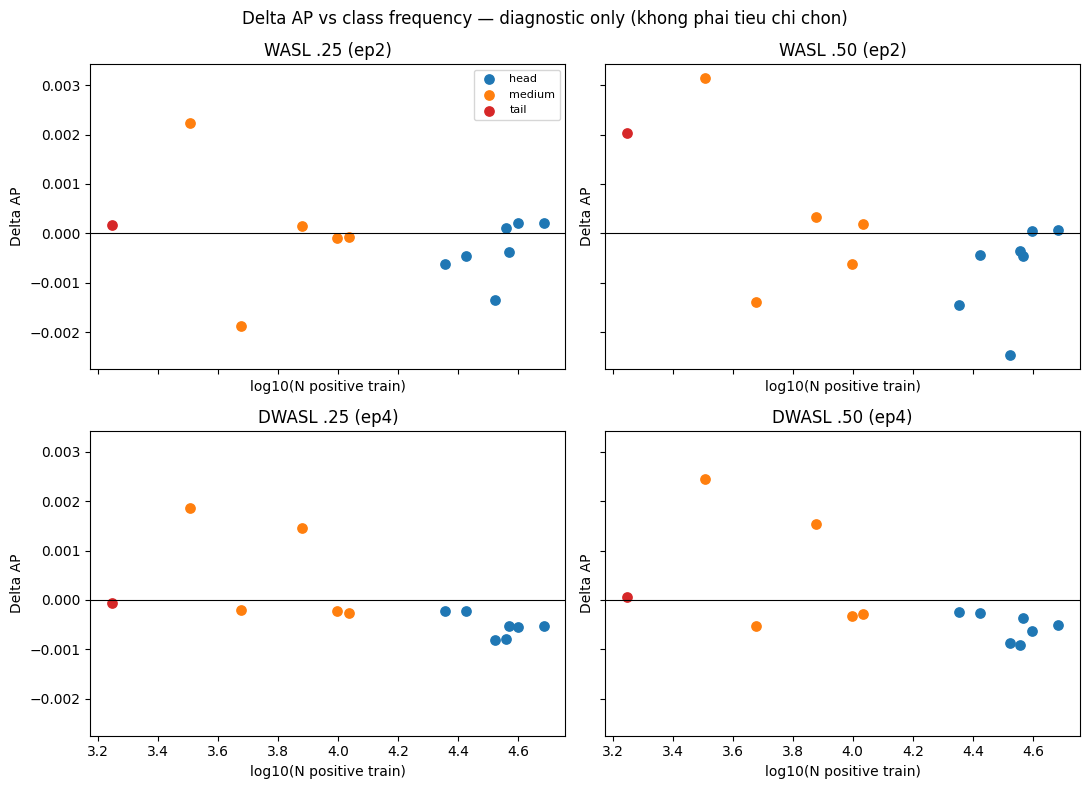

In [15]:
per_frames = {}
for t in ARMS[1:]:
    r = SEL[t]['metrics']
    df = pd.DataFrame({'Label': LABELS, 'N positive': N_POS_TRAIN.astype(int), 'Tier': TIER,
                       'AP ASL': base['per_ap'], f'AP {ARM_LABEL[t]}': r['per_ap'],
                       'Delta AP': np.array(r['per_ap']) - np.array(base['per_ap']),
                       'AUROC ASL': base['per_auroc'], f'AUROC {ARM_LABEL[t]}': r['per_auroc']})
    df = df.sort_values('N positive').reset_index(drop=True)
    per_frames[t] = df
    df.to_csv(f'{SC_DIR}/metrics/per_label_{t}.csv', index=False)
    print(f'\n--- {ARM_LABEL[t]} (ep{SEL[t]["epoch"]}) vs ASL ---')
    print(df.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
cmap = {'head':'tab:blue','medium':'tab:orange','tail':'tab:red'}
for ax, t in zip(axes.ravel(), ARMS[1:]):
    df = per_frames[t]; x = np.log10(df['N positive'].to_numpy())
    for tier in ('head','medium','tail'):
        m = (df.Tier==tier).to_numpy()
        ax.scatter(x[m], df['Delta AP'].to_numpy()[m], c=cmap[tier], label=tier, s=45)
    ax.axhline(0, color='k', lw=.8); ax.set_title(f'{ARM_LABEL[t]} (ep{SEL[t]["epoch"]})')
    ax.set_xlabel('log10(N positive train)'); ax.set_ylabel('Delta AP')
axes[0,0].legend(fontsize=8)
fig.suptitle('Delta AP vs class frequency — diagnostic only (khong phai tieu chi chon)')
fig.tight_layout(); fig.savefig(f'{SC_DIR}/metrics/delta_ap_vs_freq.png', dpi=120)
plt.show()

### Training diagnostics (§15) — đóng góp loss theo tier + grad norm

In [16]:
drows = []
for t in list(LOG):
    for e in sorted(LOG[t], key=int):
        d = LOG[t][str(e)]['diag']
        drows.append(dict(arm=t, epoch=int(e), train_loss=d['train_loss'],
                          pos_head=d['pos']['head'], pos_med=d['pos']['medium'], pos_tail=d['pos']['tail'],
                          neg_head=d['neg']['head'], neg_med=d['neg']['medium'], neg_tail=d['neg']['tail'],
                          grad_decoder=d['grad_decoder'], grad_enc=d['grad_enc'],
                          grad_adapter=d['grad_adapter'], unfrozen=d['unfrozen']))
diag = pd.DataFrame(drows).sort_values(['arm','epoch']).reset_index(drop=True)
diag.to_csv(f'{SC_DIR}/metrics/diagnostics.csv', index=False)
print(diag.to_string(index=False, float_format=lambda v: f'{v:.5f}'))

# gradient stability (§16): so voi baseline L0 cung epoch
print('\n--- grad norm ratio vs ASL (canh bao neu > 3x) ---')
b = diag[diag.arm=='L0'].set_index('epoch')
for t in ARMS[1:]:
    a = diag[diag.arm==t].set_index('epoch')
    ep = sorted(set(a.index) & set(b.index))
    if not ep: continue
    r = {c: float((a.loc[ep,c]/b.loc[ep,c].replace(0,np.nan)).max()) for c in ('grad_decoder','grad_enc','grad_adapter')}
    flag = '  <-- KHONG ON DINH' if max(r.values()) > 3 else ''
    print(f'  {ARM_LABEL[t]:<10} max ratio dec {r["grad_decoder"]:.2f} enc {r["grad_enc"]:.2f} '
          f'ad {r["grad_adapter"]:.2f}{flag}')

# ---- log full 7 metric moi epoch (§15) ----
mrows = [dict(arm=t, epoch=int(e), **{k: LOG[t][str(e)][k] for k in METRIC_KEYS}) for t in LOG for e in LOG[t]]
epoch_tab = pd.DataFrame(mrows).sort_values(['arm','epoch']).reset_index(drop=True)
epoch_tab.to_csv(f'{SC_DIR}/metrics/epoch_metrics.csv', index=False)
print('\n--- 7 metric moi epoch ---')
print(epoch_tab.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

arm  epoch  train_loss  pos_head  pos_med  pos_tail  neg_head  neg_med  neg_tail  grad_decoder  grad_enc  grad_adapter  unfrozen
 L0      4     0.04290   0.03994  0.01677   0.00638   0.02225  0.00605   0.00191       0.07541   0.00292       0.00882      True
 L0      5     0.04269   0.03972  0.01669   0.00633   0.02217  0.00602   0.00191       0.07576   0.00329       0.00926      True
 L0      6     0.04250   0.03954  0.01658   0.00623   0.02209  0.00600   0.00189       0.07495   0.00372       0.00995      True
 L0      7     0.04238   0.03942  0.01655   0.00619   0.02204  0.00598   0.00189       0.07490   0.00398       0.01058      True
 L0      8     0.04227   0.03929  0.01651   0.00621   0.02200  0.00597   0.00189       0.07484   0.00401       0.01055      True
 L1      1     0.04027   0.03447  0.01883   0.01046   0.01989  0.00720   0.00233       0.00000   0.00055       0.00720     False
 L1      2     0.03955   0.03507  0.01877   0.00933   0.01833  0.00684   0.00303       0.06980   

### Go / no-go (§14)

In [17]:
print('=== GO / NO-GO (§14) — VAL, seed 42, 1 seed screening ===\n')
verdict = {}
for t in ARMS[1:]:
    d_tail  = SEL[t]['metrics']['tail_map']      - base['tail_map']
    d_macro = SEL[t]['metrics']['macro_map']     - base['macro_map']
    d_w3    = w3_fixed(SEL[t]['metrics'])        - w3_fixed(base)
    d_rk    = SEL[t]['metrics']['tail_recall_k'] - base['tail_recall_k']
    promising = (d_tail >= 0.002) and (d_macro >= -0.002) and (d_w3 > -0.002)
    strong    = (d_tail >= 0.004) and (d_w3 > 0) and (d_rk > 0) and (d_macro >= 0)
    verdict[t] = dict(d_tail_map=d_tail, d_macro_map=d_macro, d_worst3_fixed=d_w3,
                      d_tail_recall_k=d_rk, promising=bool(promising), strong=bool(strong))
    lab = 'STRONG' if strong else ('promising' if promising else '-')
    print(f'  {ARM_LABEL[t]:<10} dTail {d_tail:+.4f} | dMacro {d_macro:+.4f} | '
          f'dWorst3 {d_w3:+.4f} | dRecall@K {d_rk:+.4f}   {lab}')

any_go = any(v['promising'] for v in verdict.values())
print('\nKET LUAN:', 'co it nhat 1 arm promising -> can nhac Stage 2 (multi-seed)' if any_go else
      'KHONG arm nao dat d_tail_map >= +0.002 voi macro giu duoc\n'
      '  -> simple class reweighting tren ASL khong cho trade-off tail co loi\n'
      '     duoi architecture nay. KHONG mo rong alpha ngay (§14 no-go).')

json.dump(dict(selected={t: dict(epoch=SEL[t]['epoch'], snap=SEL[t]['snap'],
                                 **{k: SEL[t]['metrics'][k] for k in METRIC_KEYS},
                                 worst3_fixed=w3_fixed(SEL[t]['metrics'])) for t in ARMS},
               worst3_fixed_labels=[LABELS[j] for j in w3_idx],
               verdict=verdict, any_promising=bool(any_go),
               class_weights={str(a): W_VEC[a].tolist() for a in W_VEC}),
          open(f'{SC_DIR}/metrics/stage1_result.json','w'), indent=1)
print('\nsaved -> metrics/stage1_result.json, main_table.csv, delta_table.csv, '
      'per_label_*.csv, diagnostics.csv, epoch_metrics.csv, delta_ap_vs_freq.png')
print('\nSTOP POINT (§22): doc ket qua truoc, KHONG tu dong chay Stage 2 hay loss family moi.')

=== GO / NO-GO (§14) — VAL, seed 42, 1 seed screening ===

  WASL .25   dTail +0.0002 | dMacro -0.0001 | dWorst3 +0.0008 | dRecall@K -0.0027   -
  WASL .50   dTail +0.0020 | dMacro -0.0001 | dWorst3 +0.0018 | dRecall@K +0.0000   promising
  DWASL .25  dTail -0.0001 | dMacro -0.0001 | dWorst3 +0.0005 | dRecall@K +0.0027   -
  DWASL .50  dTail +0.0001 | dMacro -0.0001 | dWorst3 +0.0007 | dRecall@K +0.0053   -

KET LUAN: co it nhat 1 arm promising -> can nhac Stage 2 (multi-seed)

saved -> metrics/stage1_result.json, main_table.csv, delta_table.csv, per_label_*.csv, diagnostics.csv, epoch_metrics.csv, delta_ap_vs_freq.png

STOP POINT (§22): doc ket qua truoc, KHONG tu dong chay Stage 2 hay loss family moi.
